# Networking, SSH & Remote File Sync

Data and AI work happens on remote machines: cloud servers, GPU boxes, clusters. You need to know how programs talk over a network, how to connect securely with **SSH**, and how to copy data efficiently with **rsync**.

**After this lesson you can:**

1. Explain IP addresses, ports, DNS and sockets.
2. Find listening ports and test HTTP services with `ss` and `curl`.
3. Create SSH keys, configure hosts in `~/.ssh/config` and use port forwarding.
4. Synchronise folders with `rsync` and measure how much it transfers.

In [1]:
import os
import subprocess
import tempfile
from pathlib import Path

WORK = Path(tempfile.mkdtemp())          # a folder on the Linux file system (not on a Windows drive)
REPO = Path.cwd().parent                 # the course repository: real data for some examples

class Output(str):
    """The text output of a command; the notebook does not display it a second time."""
    def _ipython_display_(self):
        pass

def sh(cmd: str, cwd: Path = WORK, quiet: bool = False, check: bool = False) -> Output:
    """Run a command with bash, print the command and its output."""
    r = subprocess.run(["bash", "-c", cmd], cwd=cwd, capture_output=True, text=True)
    shorten = lambda t: t.replace(str(WORK), "<work>").replace(str(REPO), "<repo>")
    out = shorten((r.stdout + r.stderr).rstrip())
    if not quiet:
        print(f"$ {shorten(cmd)}" + (f"\n{out}" if out else ""))
    if check and r.returncode:
        raise RuntimeError(f"command failed with exit code {r.returncode}")
    return Output(r.stdout)

## 1. Addresses, Ports and DNS

| Concept | Meaning | Example |
| :--- | :--- | :--- |
| **IP address** | the address of a machine on a network | `192.168.1.20`, `::1` |
| **port** | a number that selects one service on a machine | 22 SSH, 80 HTTP, 443 HTTPS, 5432 PostgreSQL |
| **socket** | one end of a connection: IP + port | `127.0.0.1:8000` |
| **DNS** | translates names into IP addresses | `github.com` → `140.82.x.x` |
| **localhost** | the machine itself: `127.0.0.1` | |

A server **listens** on a port; a client **connects** to it.

In [2]:
sh("hostname -I 2>/dev/null | cut -d' ' -f1 || hostname")
sh("getent hosts localhost | head -2")
sh("getent hosts pypi.org | head -1 || echo 'no DNS / offline'")

$ hostname -I 2>/dev/null | cut -d' ' -f1 || hostname
172.21.130.1
$ getent hosts localhost | head -2
::1             localhost
$ getent hosts pypi.org | head -1 || echo 'no DNS / offline'
2a04:4e42:200::223 pypi.org


## 2. Listening Ports and HTTP

The cell starts a real web server on a free port in the background. Then it uses `ss` to find the listening socket and `curl` to send requests.

In [3]:
import socket
import time

(WORK / "site").mkdir()
(WORK / "site" / "index.html").write_text("<h1>Hello from a local server</h1>\n")
(WORK / "site" / "data.json").write_text('{"model": "gbm", "auc": 0.91}\n')
with socket.socket() as s:
    s.bind(("127.0.0.1", 0))
    PORT = s.getsockname()[1]
server = subprocess.Popen(["python3", "-m", "http.server", str(PORT), "--bind", "127.0.0.1"], cwd=WORK / "site",
                          stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
time.sleep(1)
sh(f"ss -tln | grep -E 'State|:{PORT} '")
sh(f"curl -s -i http://127.0.0.1:{PORT}/data.json | head -6")
sh(f"curl -s -o /dev/null -w 'status=%{{http_code}} time=%{{time_total}}s\\n' http://127.0.0.1:{PORT}/missing")

$ ss -tln | grep -E 'State|:43053 '
State  Recv-Q Send-Q  Local Address:Port  Peer Address:PortProcess
LISTEN 0      5           127.0.0.1:43053      0.0.0.0:*


$ curl -s -i http://127.0.0.1:43053/data.json | head -6
HTTP/1.0 200 OK
Server: SimpleHTTP/0.6 Python/3.12.16
Date: Mon, 16 Nov 2026 14:04:36 GMT
Content-type: application/json
Content-Length: 30
Last-Modified: Mon, 16 Nov 2026 14:04:35 GMT
$ curl -s -o /dev/null -w 'status=%{http_code} time=%{time_total}s\n' http://127.0.0.1:43053/missing
status=404 time=0.001053s


`ss -tln` shows TCP sockets (`-t`) that listen (`-l`), with numeric ports (`-n`). `curl -i` prints the response headers; `-w` prints selected timings, which is useful for quick performance checks.

## 3. SSH: Secure Remote Access

**SSH** (Secure Shell) opens an encrypted connection to a remote machine. Use **key-based authentication** instead of passwords:

1. Create a key pair. The **private key** stays on your computer (permissions `600`); the **public key** goes to the server, into `~/.ssh/authorized_keys`.
2. The server proves its identity with its host key; your client remembers it in `~/.ssh/known_hosts`.

The cell creates a real Ed25519 key pair in the temporary folder.

In [4]:
sh("ssh-keygen -q -t ed25519 -N '' -C 'course-demo-key' -f demo_key && ls -l demo_key*")
sh("ssh-keygen -l -f demo_key.pub")                      # fingerprint: compare it, do not compare the whole key
sh("cut -c1-60 demo_key.pub")

$ ssh-keygen -q -t ed25519 -N '' -C 'course-demo-key' -f demo_key && ls -l demo_key*
-rw------- 1 root root 411 Nov 16 17:04 demo_key
-rw-r--r-- 1 root root  97 Nov 16 17:04 demo_key.pub
$ ssh-keygen -l -f demo_key.pub
256 SHA256:XpiZT5sbpkDAKoR7/peYNNm//OxGnEi8+JY5Vh7gF1g course-demo-key (ED25519)
$ cut -c1-60 demo_key.pub
ssh-ed25519 AAAAC3NzaC1lZDI1NTE5AAAAIIqhdYwX4FeXeqGGUhx9U+OF


A `~/.ssh/config` file gives hosts short names and settings:

```
Host gpu-box
    HostName 203.0.113.10
    User ayse
    IdentityFile ~/.ssh/id_ed25519
    LocalForward 8888 localhost:8888      # Jupyter on the server -> http://localhost:8888 on your laptop
    ServerAliveInterval 60

Host bastion
    HostName bastion.example.com
Host db-internal
    HostName 10.0.3.15
    ProxyJump bastion                     # connect through the bastion host
```

Then `ssh gpu-box` connects, and **port forwarding** makes the remote Jupyter server available on your laptop. `ssh gpu-box 'nvidia-smi'` runs one command remotely. `ProxyJump` reaches machines in a private network through a **bastion host**.

## 4. rsync: Efficient File Synchronisation

`rsync` copies only what changed. For changed files it sends only the changed blocks (**delta transfer**). The same command works locally and over SSH: `rsync -avz data/ gpu-box:/data/`.

| Option | Meaning |
| :--- | :--- |
| `-a` | archive: recursive, keep permissions and timestamps |
| `-v`, `--stats` | show what happens |
| `-z` | compress during transfer |
| `--delete` | delete files at the destination that no longer exist at the source |
| `-n` (`--dry-run`) | show what would happen, change nothing |

The experiment synchronises a folder of 200 files (40 MB, synthetic), then changes one file and synchronises again.

In [5]:
import re

src, dst = WORK / "dataset", WORK / "backup"
src.mkdir()
for i in range(200):
    (src / f"part-{i:03d}.bin").write_bytes(os.urandom(200_000))

def rsync_stats(extra: str = "") -> dict:
    out = sh(f"rsync -a --no-whole-file --stats {extra} dataset/ backup/", quiet=True)
    grab = lambda label: int(re.search(rf"{label}: ([\d,]+)", out).group(1).replace(",", ""))
    return {"sent": grab("Total bytes sent"), "files": grab("Number of regular files transferred"),
            "total": grab("Total file size")}

runs = {}
runs["first sync (all new)"] = rsync_stats()
runs["no change"] = rsync_stats()
time.sleep(1.1)                                      # rsync compares timestamps in whole seconds
with open(src / "part-007.bin", "r+b") as f:          # change 1 KB in the middle of one file
    f.seek(100_000)
    f.write(os.urandom(1_000))
runs["1 KB changed in 1 file"] = rsync_stats()
(src / "part-199.bin").unlink()
sh("rsync -an --delete --itemize-changes dataset/ backup/ | head -3")    # dry run: what --delete would do
for name, s in runs.items():
    print(f"{name:<24} files transferred {s['files']:>3} | bytes sent {s['sent']:>11,} of {s['total']:,}")
server.terminate()

$ rsync -an --delete --itemize-changes dataset/ backup/ | head -3
*deleting   part-199.bin
.d..t...... ./
first sync (all new)     files transferred 200 | bytes sent  40,022,083 of 40,000,000
no change                files transferred   0 | bytes sent       3,880 of 40,000,000
1 KB changed in 1 file   files transferred   1 | bytes sent       7,159 of 40,000,000


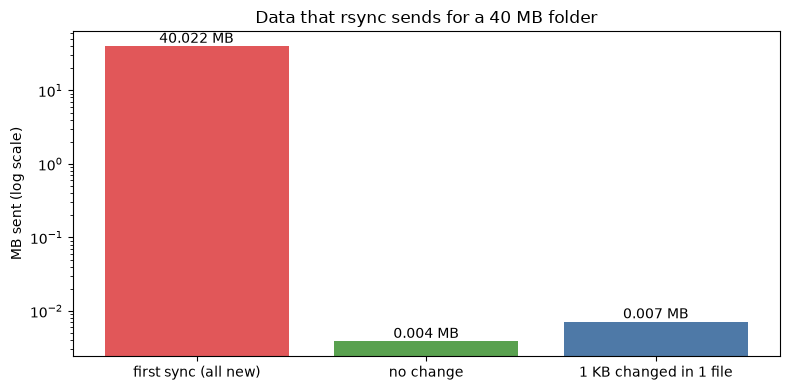

In [6]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(runs.keys(), [s["sent"] / 1e6 for s in runs.values()], color=["#E15759", "#59A14F", "#4E79A7"])
for i, s in enumerate(runs.values()):
    ax.text(i, s["sent"] / 1e6, f"{s['sent'] / 1e6:.3f} MB", ha="center", va="bottom")
ax.set(yscale="log", title="Data that rsync sends for a 40 MB folder", ylabel="MB sent (log scale)")
plt.tight_layout()
plt.show()

The first run sends all 40 MB. When nothing changed, rsync sends only file lists (a few kilobytes). When 1 KB changed in one file, rsync sends roughly that block plus checksums, not the 200 KB file and not the folder. Over a slow network to a cloud GPU, this is the difference between seconds and minutes.

*Insight: Use SSH keys (never passwords), give hosts names in `~/.ssh/config`, reach private machines through a bastion with `ProxyJump`, and move data with `rsync -az --dry-run` first, then without `--dry-run`.*

## Real-World Use Case or Analogy

A network is like a **postal system**: the IP address is the building, the port is the apartment number, DNS is the address book. SSH is a **sealed armoured courier** between your laptop and the server. rsync is a mover who looks at what already stands in the new apartment and brings only the missing or changed furniture.

A typical ML workflow uses all three: `ssh gpu-box` with port forwarding to open Jupyter on a cloud GPU, `rsync -az data/ gpu-box:/data/` to upload new training data, and `rsync -az gpu-box:/runs/checkpoints/ ./checkpoints/` to download results.